# Example: Superflat flow

In [1]:
from eregion.tasks import ImageCreator, AssembleFocalPlane
from eregion.tasks.custom import guess_image_type_from_filename_DEIMOS, load_image_fits_DEIMOS
from eregion.tasks.calibration import MasterBias, CalibrationResult
from eregion.tasks.preprocessing import BiasSubtraction, ScanSubtraction, SigmaClipMasking, VignetteMasking, \
    CosmicRayMasking
from eregion.tasks.superflat import SuperCombine

import numpy as np
import matplotlib.pyplot as plt
import os
import glob2
import importlib
from copy import deepcopy

def plot_focal_plane(bundle, grouping_columns=['type', 'exptime', 'seqnum'], how_many=1, zscale=False, with_mask=False, mask_key='sigma_clip_mask', **imshow_kwargs):
    fp_task = AssembleFocalPlane(num_detectors=8)
    fp_res = fp_task.run(from_images=bundle, groupby_keys=grouping_columns)
    for i in range(how_many):
        img = fp_res.data[i]
        if zscale:
            vmin, vmax = np.percentile(img.data.values, [5, 95])
        else:
            vmin, vmax = None, None
        img.show(show_det_id=True, with_mask=with_mask, mask_key=mask_key, vmin=vmin, vmax=vmax, **imshow_kwargs)
    return fp_res.data

In [2]:
basepath = '/Users/yashvi/Desktop/Detector Characterization Tools/DTU_dettest/DTU_fullfp_bringup/PTC/SCI'
runid = '20260718*'
rawpath = glob2.glob(os.path.join(basepath, runid))[0]
outpath = rawpath.replace('/DTU_dettest/','/DTU_detreduce/')
if not os.path.exists(outpath):
    os.makedirs(outpath)

Load existing master bias

In [3]:
# load master bias result obj
mb_res = CalibrationResult.load(outpath)
mb_res.master_bias

,type,exptime,obstime,seqnum,led,backbias,serial_overscan_subtracted,det_id,filename,object
0,master_bias,0.0,2026-07-18T001412.976,0,GREEN,-50.0,True,det_1,/Users/yashvi/Desktop/Detector Characterizatio...,<eregion.datamodels.image.DetImage object at 0...
1,master_bias,0.0,2026-07-18T001412.976,0,GREEN,-50.0,True,det_2,/Users/yashvi/Desktop/Detector Characterizatio...,<eregion.datamodels.image.DetImage object at 0...
2,master_bias,0.0,2026-07-18T001412.976,0,GREEN,-50.0,True,det_3,/Users/yashvi/Desktop/Detector Characterizatio...,<eregion.datamodels.image.DetImage object at 0...
3,master_bias,0.0,2026-07-18T001412.976,0,GREEN,-50.0,True,det_4,/Users/yashvi/Desktop/Detector Characterizatio...,<eregion.datamodels.image.DetImage object at 0...
4,master_bias,0.0,2026-07-18T001412.976,0,GREEN,-50.0,True,det_5,/Users/yashvi/Desktop/Detector Characterizatio...,<eregion.datamodels.image.DetImage object at 0...
5,master_bias,0.0,2026-07-18T001412.976,0,GREEN,-50.0,True,det_6,/Users/yashvi/Desktop/Detector Characterizatio...,<eregion.datamodels.image.DetImage object at 0...
6,master_bias,0.0,2026-07-18T001412.976,0,GREEN,-50.0,True,det_7,/Users/yashvi/Desktop/Detector Characterizatio...,<eregion.datamodels.image.DetImage object at 0...
7,master_bias,0.0,2026-07-18T001412.976,0,GREEN,-50.0,True,det_8,/Users/yashvi/Desktop/Detector Characterizatio...,<eregion.datamodels.image.DetImage object at 0...


In [4]:
## Loading a pair at an exptime
creator = ImageCreator(detector_config='../src/eregion/configs/detectors/deimos_sci.yaml', n_jobs=1, max_batch_size=1)
oscan_sub = ScanSubtraction(which_scan='serial_overscan', method='median_by_axis', trim_start=6, n_jobs=1)
vig_mask = VignetteMasking()
sg_mask = SigmaClipMasking(sigma_clip_args={'sigma_lower':5.0, 'sigma_upper':5.0})
bias_sub = BiasSubtraction(only_image_area=True, n_jobs=1)
superflat_mean = SuperCombine(method='mean', n_jobs=1)
superflat_welf = SuperCombine(method='welford', n_jobs=1)

for flres in creator.lazy_run(input_source='/Users/yashvi/Desktop/Detector Characterization Tools/DTU_dettest/DTU_fullfp_bringup/PTC/SCI/20260718*/*SCI_1_flat_0.032*.fits',
                             identifier_func=guess_image_type_from_filename_DEIMOS,
                             fileloader_func=load_image_fits_DEIMOS,
                             data_on_demand=True):
    flres = oscan_sub.run(images=flres.data)
    flres = vig_mask.run(images=flres.data)
    flres = sg_mask.run(images=flres.data)
    flres = bias_sub.run(images=flres.data, master_bias=mb_res.master_bias)
    sfres_mean = superflat_mean.run(deepcopy(flres.data))
    sfres_welf = superflat_welf.run(deepcopy(flres.data))


2026-10-22 11:56:47,011 - DetectorConfig - INFO - Config loaded from file '../src/eregion/configs/detectors/deimos_sci.yaml'
2026-10-22 11:56:47,012 - ScanSubtraction - INFO - Setting method 'median_by_axis' for task ScanSubtraction.
2026-10-22 11:56:47,012 - sigma_clip_masking - INFO - Setting method 'ccd' for task sigma_clip_masking.
2026-10-22 11:56:47,012 - SuperCombine - INFO - Setting method 'mean' for task SuperCombine.
2026-10-22 11:56:47,013 - SuperCombine - INFO - Setting method 'welford' for task SuperCombine.
2026-10-22 11:56:47,013 - SuperCombine - INFO - Setting method 'welford' for task SuperCombine.
2026-10-22 11:56:47,013 - image_creator - INFO - Item /Users/yashvi/Desktop/Detector Characterization Tools/DTU_dettest/DTU_fullfp_bringup/PTC/SCI/20260718*/*SCI_1_flat_0.032*.fits is a glob pattern
2026-10-22 11:56:47,205 - image_creator - INFO - Building object DetImage with 2 CCDOutput outputs from file /Users/yashvi/Desktop/Detector Characterization Tools/DTU_dettest/DTU

In [8]:
img_mean = sfres_mean.data[0]
data_mean = img_mean.get_masked_data(data_var='all', mask_key='combined')

img_welf = sfres_welf.data[0]
data_welf = img_welf.get_masked_data(data_var='all', mask_key='combined')

2026-10-22 12:03:31,138 - eregion.datamodels.image - WARNING - No masks found in any of the outputs to build the full mask from.
2026-10-22 12:03:31,139 - eregion.datamodels.image - WARNING - No masks found in any of the outputs to build the full mask from.


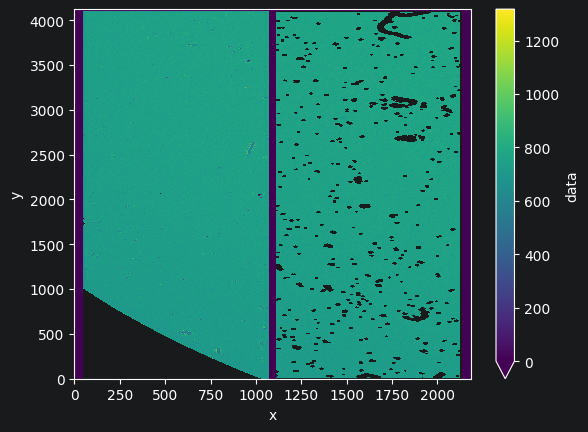

In [19]:
data_mean['data'].plot.imshow(vmin=0)
# data_mean['std'].plot.imshow(vmax=100)

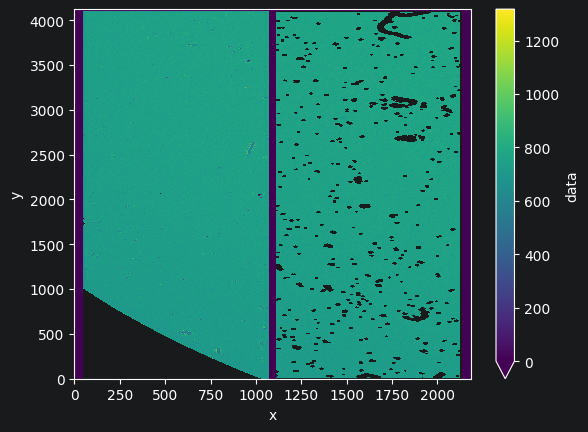

In [18]:
data_welf['data'].plot.imshow(vmin=0)

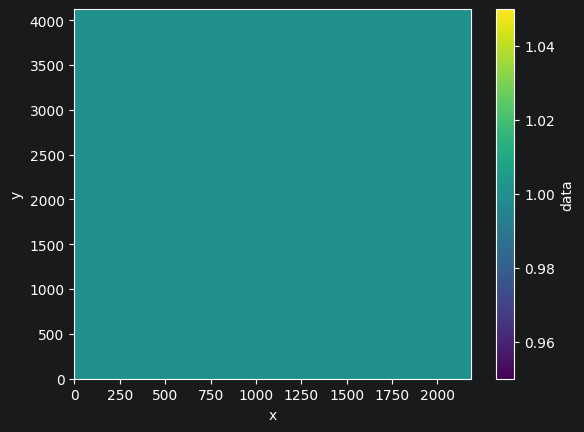

In [27]:
(data_mean['data'].where(data_mean['data'].notnull(),other=0)==data_welf['data'].where(data_welf['data'].notnull(),other=0)).plot.imshow()